# Plant Treatment Comparison

How does dry plant weight differ across treatment groups?

Data: [datasets/PlantGrowth](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/PlantGrowth.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Only ten observations per group; sample mean rankings can be unstable.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Plant Treatment Comparison',
 'executed_utc': '2026-11-21T10:14:11.583283+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/PlantGrowth.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/PlantGrowth.html',
 'sha256': 'd1738e182d566ed045ce9a492671fc8f793ea33f42aaaa5b499b18e9438ee7fc',
 'raw_rows': 30,
 'analysis_rows': 30,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,30
1,weight,float64,0,0.0,29
2,group,object,0,0.0,3


## SQL and analysis
Complete-case descriptive comparison of weight by group; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "group" AS segment, COUNT(*) AS rows_used, AVG("weight") AS metric, MIN("weight") AS minimum, MAX("weight") AS maximum FROM observations GROUP BY "group" ORDER BY "group";

The largest observed mean weight is 5.526 for trt2. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,ctrl,10,5.032,4.17,6.11
1,trt1,10,4.661,3.59,6.03
2,trt2,10,5.526,4.92,6.31


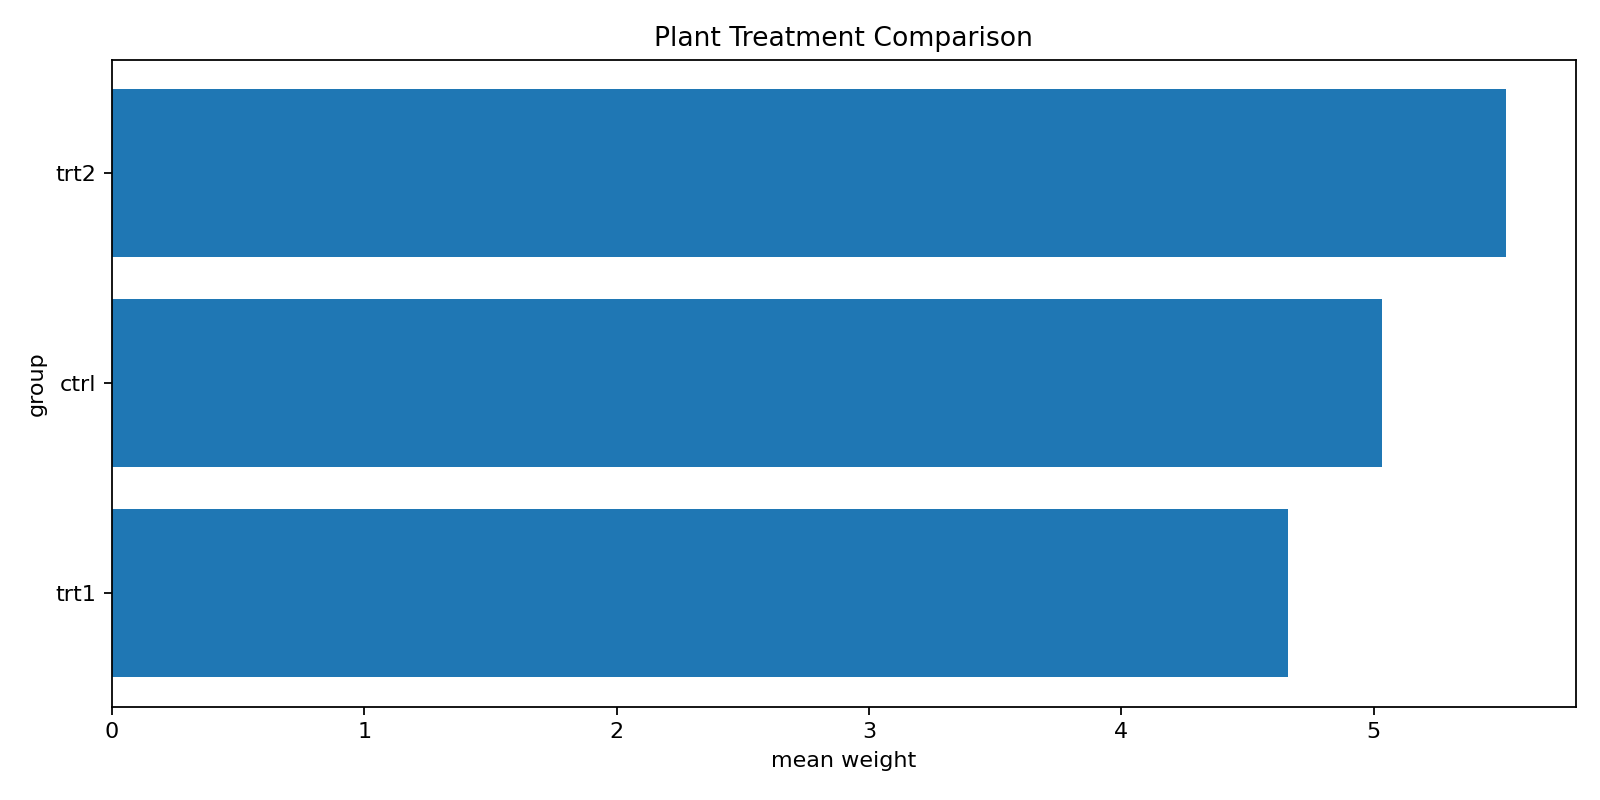

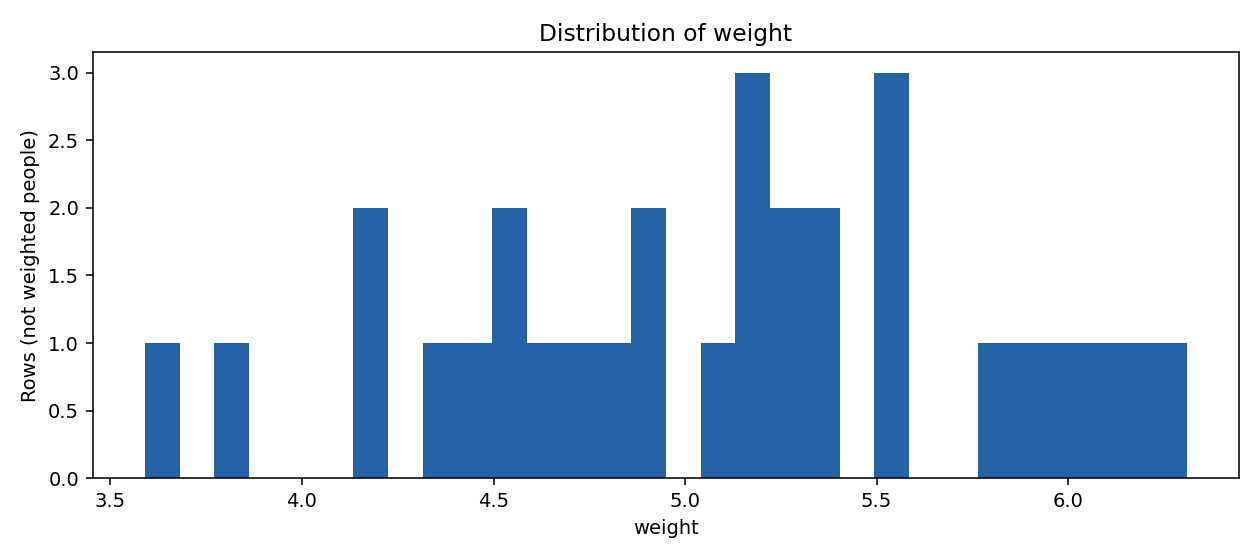

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Only ten observations per group; sample mean rankings can be unstable.

**Next action:** Repeat the experiment with a preregistered design.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.